<a href="https://colab.research.google.com/github/zoya-fatyma/netflix-titles-eda/blob/main/Netflix_Titles_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving netflix_titles.csv to netflix_titles.csv


Netflix Titles — Exploratory Data Analysis
Project Overview
This project performs Exploratory Data Analysis (EDA) on the Netflix titles dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The goal is to explore Netflix content and identify patterns related to:


Movies and TV Shows
Countries
Release years
Ratings
Movie duration
TV Show seasons
Genres
Directors and actors
Titles added by year and month

The analysis includes data cleaning, exploration, aggregation, comparison, and visualization.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('netflix_titles.csv')

In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.shape

(8807, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


In [ ]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [ ]:
df.isna().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df.duplicated().sum()

np.int64(0)

Data Cleaning

Before starting the analysis, the dataset is cleaned and prepared for EDA. This step includes checking missing values, handling duplicates, converting date columns into the correct format, and preparing useful features for further analysis.

In [ ]:
df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

In [ ]:
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()

In [ ]:
df.isna().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,98
release_year,0
rating,4
duration,3


In [ ]:
df.duplicated().sum()

np.int64(0)

Content Overview

This section explores the overall composition of the Netflix dataset. We will examine the total number of titles and compare Movies with TV Shows to understand the type of content available in the dataset.

In [ ]:
df.shape[0]

8807

In [ ]:
df['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


In [ ]:
df['type'].value_counts(normalize=True) * 100

,proportion
type,
Movie,69.615079
TV Show,30.384921


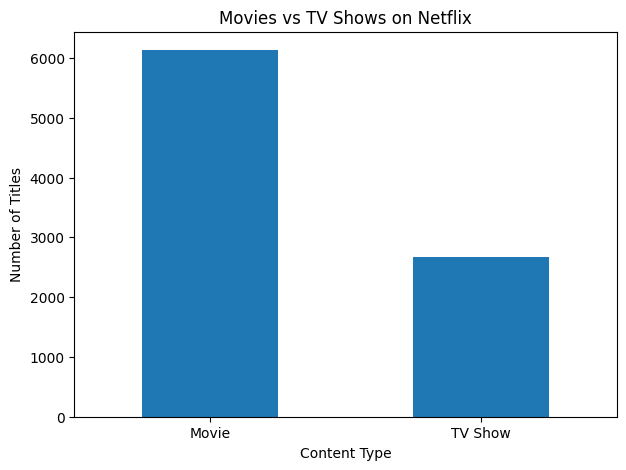

In [ ]:
df['type'].value_counts().plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()

Country Analysis

This section explores the countries associated with Netflix titles. Since some titles are associated with multiple countries, the country data is split and expanded to identify the countries that appear most frequently in the dataset.

In [ ]:
df['country'].isna().sum()

np.int64(831)

In [ ]:
df['country'].str.contains(',').sum()

1320

In [ ]:
countries = df['country'].str.split(',')
countries = countries.explode()
countries = countries.str.strip()

In [ ]:
countries.value_counts().head(10)

,count
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


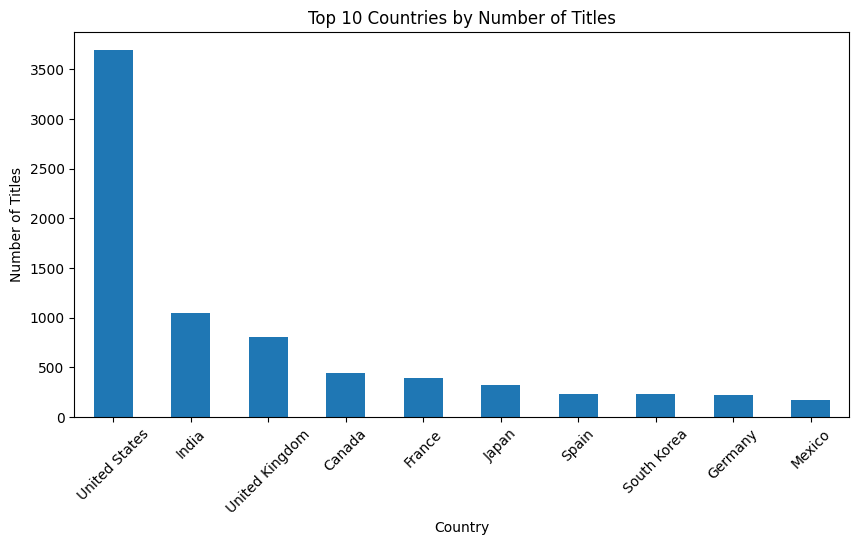

In [ ]:
countries.value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Countries by Number of Titles')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Release Year Analysis

This section examines the release years of Netflix titles to understand the range of content available in the dataset and identify years with a higher number of titles. A trend visualization is also used to observe how the number of titles changes across release years.

In [ ]:
df['release_year'].min()

1925

In [ ]:
df['release_year'].max()

2021

In [ ]:
df['release_year'].value_counts().head(10)

,count
release_year,
2018,1147
2017,1032
2019,1030
2020,953
2016,902
2021,592
2015,560
2014,352
2013,288


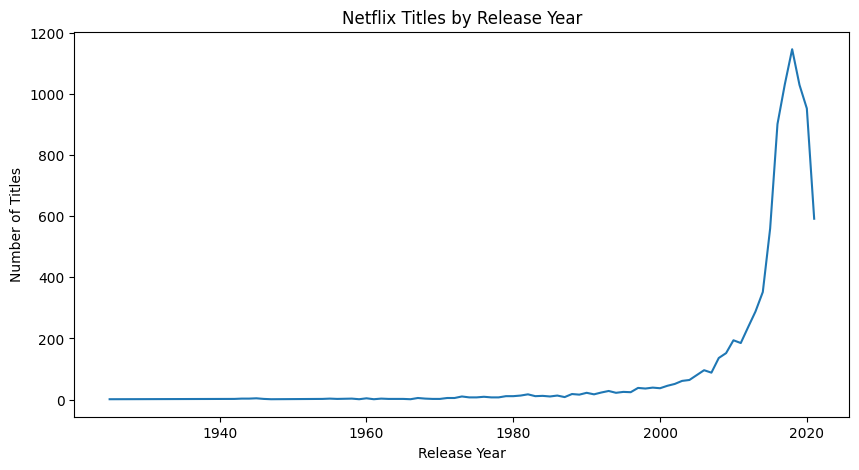

In [ ]:
year_counts = df['release_year'].value_counts().sort_index()

year_counts.plot(
    kind='line',
    figsize=(10, 5)
)

plt.title('Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

Ratings Analysis

This section explores the content ratings of Netflix titles. The analysis helps us understand which age ratings are most common and how Netflix content is distributed across different rating categories.

In [ ]:
rating_type = pd.crosstab(df['rating'], df['type'])

rating_type

type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


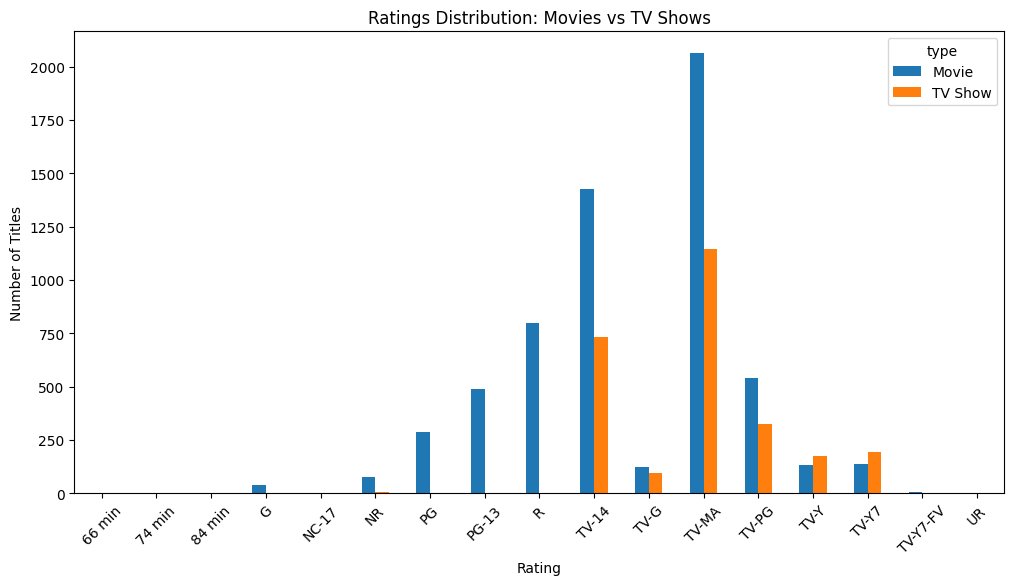

In [ ]:
rating_type.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Ratings Distribution: Movies vs TV Shows')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Movie Duration Analysis

This section analyzes the duration of Netflix movies. It examines the average movie duration, identifies longer movies, and groups movies into duration categories to understand the overall distribution of movie lengths.

In [ ]:
df['duration_minutes'] = (
    df['duration']
    .str.extract(r'(\d+)')[0]
    .astype(float)
)

In [ ]:
df[['type', 'duration', 'duration_minutes']].head()

,type,duration,duration_minutes
0,Movie,90 min,90.0
1,TV Show,2 Seasons,2.0
2,TV Show,1 Season,1.0
3,TV Show,1 Season,1.0
4,TV Show,2 Seasons,2.0


In [ ]:
df.loc[df['type'] == 'Movie', 'duration_minutes'].mean()

np.float64(99.57718668407311)

In [ ]:
df.loc[
    (df['type'] == 'Movie') & (df['duration_minutes'] > 120),
    ['title', 'duration_minutes']
]

,title,duration_minutes
7,Sankofa,125.0
12,Je Suis Karl,127.0
22,Avvai Shanmughi,161.0
24,Jeans,166.0
26,Minsara Kanavu,147.0
...,...,...
8772,Yamla Pagla Deewana 2,147.0
8773,Yanda Kartavya Aahe,151.0
8788,You Carry Me,157.0
8798,Zed Plus,131.0


In [ ]:
df.loc[
    df['type'] == 'Movie',
    ['title', 'duration_minutes']
].sort_values(
    by='duration_minutes',
    ascending=False
).head(10)

,title,duration_minutes
4253,Black Mirror: Bandersnatch,312.0
717,Headspace: Unwind Your Mind,273.0
2491,The School of Mischief,253.0
2487,No Longer kids,237.0
2484,Lock Your Girls In,233.0
2488,Raya and Sakina,230.0
166,Once Upon a Time in America,229.0
7932,Sangam,228.0
1019,Lagaan,224.0
4573,Jodhaa Akbar,214.0


In [ ]:
bins = [0, 60, 90, 120, 180, np.inf]

labels = [
    '0-60 min',
    '61-90 min',
    '91-120 min',
    '121-180 min',
    '180+ min'
]

df['duration_category'] = pd.cut(
    df['duration_minutes'],
    bins=bins,
    labels=labels
)

In [ ]:
df.loc[
    df['type'] == 'Movie',
    'duration_category'
].value_counts()

,count
duration_category,
91-120 min,2996
61-90 min,1503
121-180 min,1095
0-60 min,487
180+ min,47


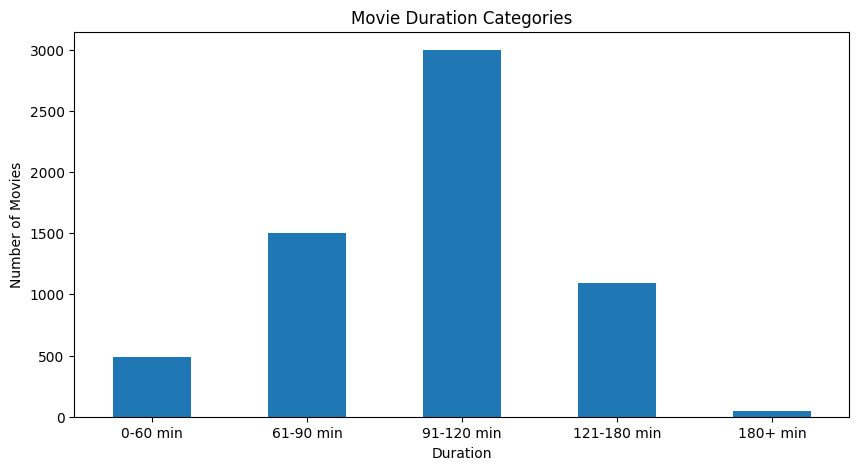

In [ ]:
df.loc[
    df['type'] == 'Movie',
    'duration_category'
].value_counts().sort_index().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Movie Duration Categories')
plt.xlabel('Duration')
plt.ylabel('Number of Movies')
plt.xticks(rotation=0)

plt.show()

TV Show Seasons Analysis
This section analyzes the number of seasons in Netflix TV Shows. It examines the average number of seasons, identifies the longest-running shows, and explores how TV Shows are distributed by number of seasons.

In [ ]:

df['duration_seasons'] = (
    df['duration']
    .str.extract(r'(\d+)')[0]
    .astype(float)
)

In [ ]:
df.loc[df['type'] == 'TV Show', 'duration_seasons'].mean()

np.float64(1.764947683109118)

In [ ]:
df.loc[df['type'] == 'TV Show', 'duration_seasons'].max()

17.0

In [ ]:
df.loc[df['type'] == 'TV Show', 'duration_seasons'].value_counts().sort_index()

,count
duration_seasons,
1.0,1793
2.0,425
3.0,199
4.0,95
5.0,65
6.0,33
7.0,23
8.0,17
9.0,9


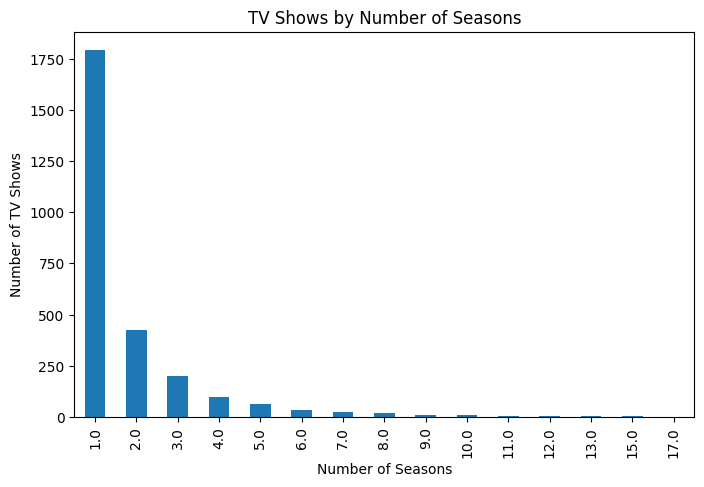

In [ ]:
df.loc[df['type'] == 'TV Show', 'duration_seasons'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('TV Shows by Number of Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')
plt.show()

Genre Analysis

This section explores the different genres available in the Netflix dataset. Since a title can belong to multiple genres, the genre values are split and expanded to identify the most frequently occurring genres.

In [ ]:
genre_list = df['listed_in'].str.split(',')

In [ ]:
genre_list = genre_list.explode()

In [ ]:
genre_list = genre_list.str.strip()

In [ ]:
genre_list.value_counts().head(10)

,count
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


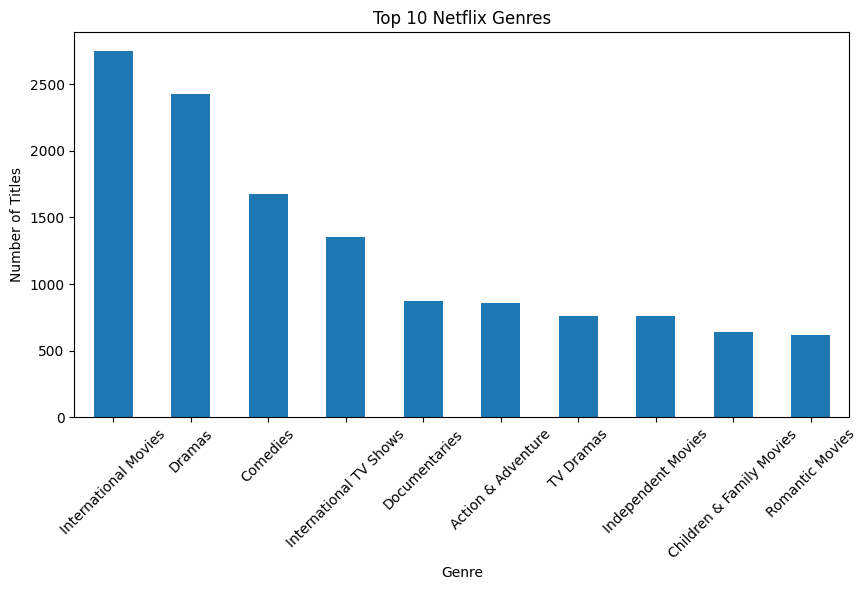

In [ ]:
genre_list.value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Netflix Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Director Analysis

This section explores the directors of Netflix titles. It identifies the directors with the highest number of titles in the dataset while excluding unknown values from the main analysis.

In [ ]:
df['director'].isna().sum()

np.int64(2634)

In [ ]:
df['director'].value_counts().head(10)

,count
director,
Rajiv Chilaka,19
"Raúl Campos, Jan Suter",18
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
Martin Scorsese,12
Youssef Chahine,12
Jay Chapman,12


In [ ]:
df[df['director'] != 'unknown']['director'].value_counts().head(10)

,count
director,
Rajiv Chilaka,19
"Raúl Campos, Jan Suter",18
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
Martin Scorsese,12
Youssef Chahine,12
Jay Chapman,12


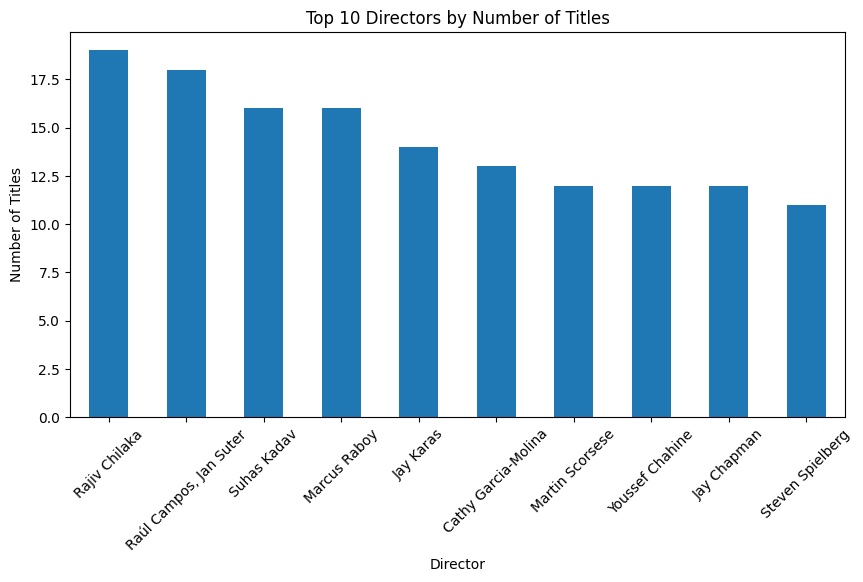

In [ ]:
df[df['director'] != 'unknown']['director'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Directors by Number of Titles')
plt.xlabel('Director')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Actor Analysis

This section explores the actors appearing in Netflix titles. The cast information is split into individual actors to identify the actors who appear most frequently in the dataset.

In [ ]:
df['cast'].isna().sum()

np.int64(825)

In [ ]:
actor_list = df['cast'].str.split(',').explode().str.strip()

In [ ]:
actor_list.value_counts().head(10)

,count
cast,
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Takahiro Sakurai,32
Naseeruddin Shah,32
Rupa Bhimani,31
Om Puri,30
Akshay Kumar,30
Yuki Kaji,29


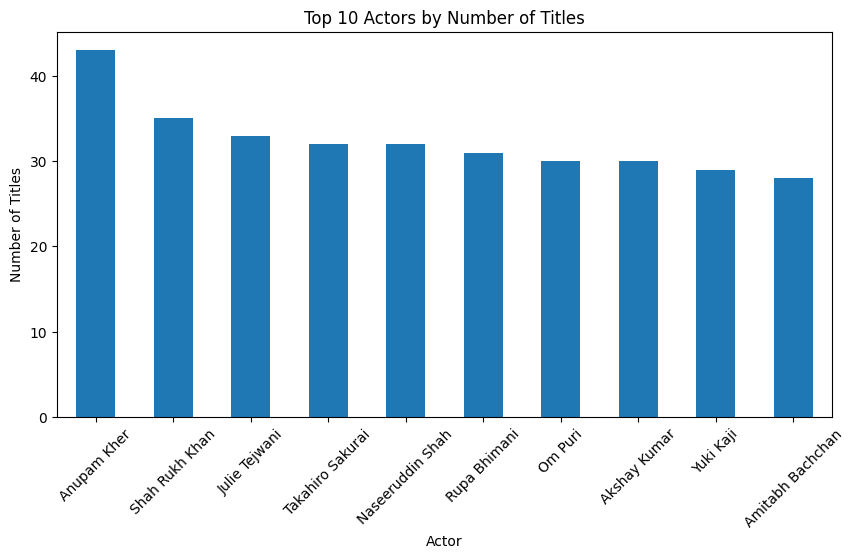

In [ ]:
actor_list[actor_list != 'Unknown'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Actors by Number of Titles')
plt.xlabel('Actor')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Year Added Analysis

This section examines the years in which Netflix titles were added to the dataset. It helps identify the years with the highest number of titles added and shows how Netflix's content additions changed over time.

In [ ]:
df['year_added'].isna().sum()

np.int64(98)

In [ ]:
df['year_added'].value_counts().head(10)

,count
year_added,
2019.0,1999
2020.0,1878
2018.0,1625
2021.0,1498
2017.0,1164
2016.0,418
2015.0,73
2014.0,23
2011.0,13


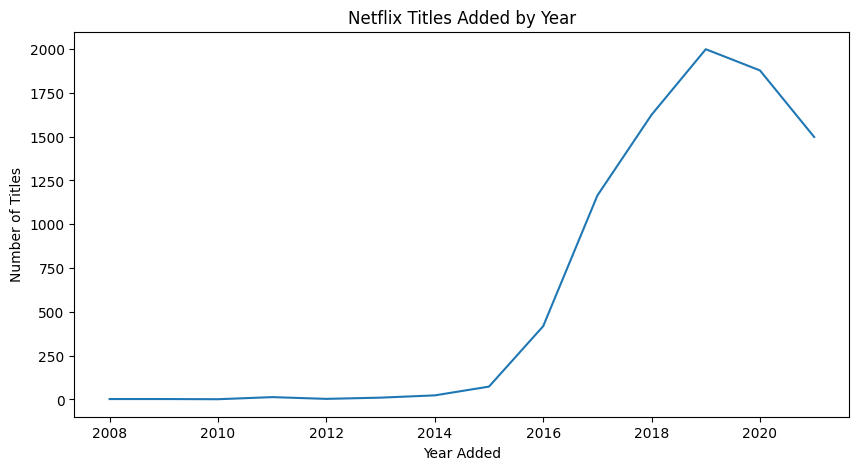

In [ ]:
year_added_counts = df['year_added'].value_counts().sort_index()

year_added_counts.plot(
    kind='line',
    figsize=(10, 5)
)

plt.title('Netflix Titles Added by Year')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')

plt.show()

Month Added Analysis

This section examines the months in which Netflix titles were added to the dataset. It helps identify which months had the highest and lowest numbers of titles added.

In [ ]:
df['month_added'].isna().sum()

np.int64(98)

In [ ]:
df['month_added'].value_counts()

,count
month_added,
July,819
December,797
September,765
April,759
October,755
August,749
March,734
January,727
June,724


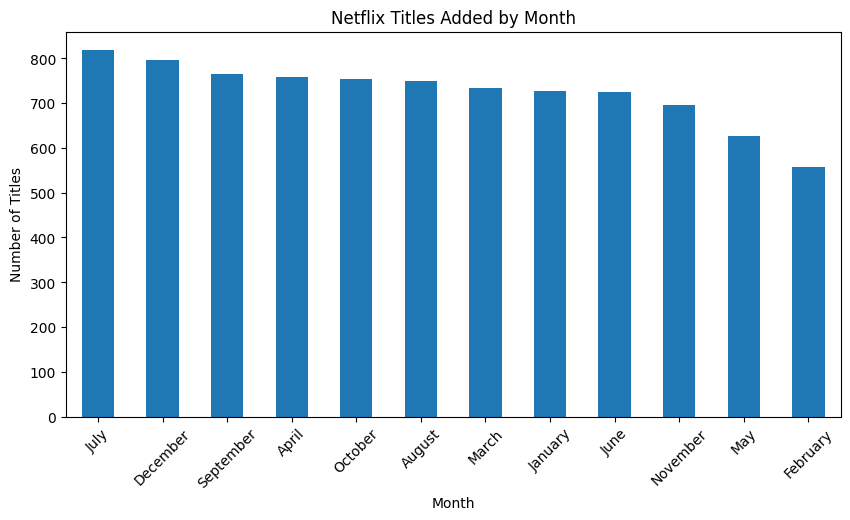

In [ ]:
df['month_added'].value_counts().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Netflix Titles Added by Month')
plt.xlabel('Month')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Ratings Comparison: Movies vs TV Shows

This section compares the ratings of Movies and TV Shows to understand how different rating categories are distributed across the two content types.

In [ ]:
rating_type = pd.crosstab(df['rating'], df['type'])
rating_type

type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


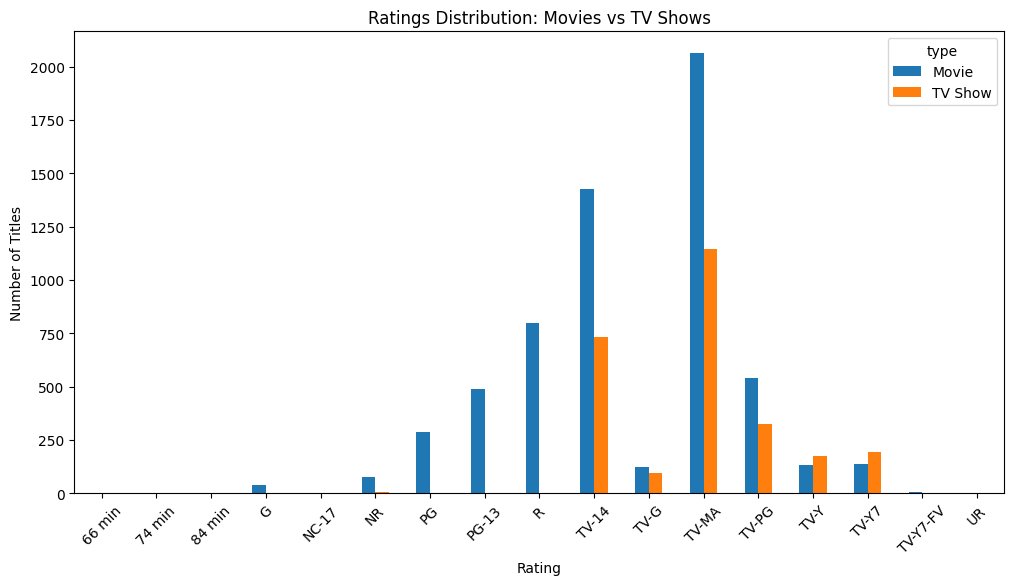

In [ ]:
rating_type.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Ratings Distribution: Movies vs TV Shows')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Release Year Comparison: Movies vs TV Shows

This section compares Movies and TV Shows across different release years. The comparison helps identify how the number of Movies and TV Shows has changed over the years.

In [ ]:
year_type = pd.crosstab(df['release_year'], df['type'])
year_type

type,Movie,TV Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
...,...,...
2017,767,265
2018,767,380
2019,633,397


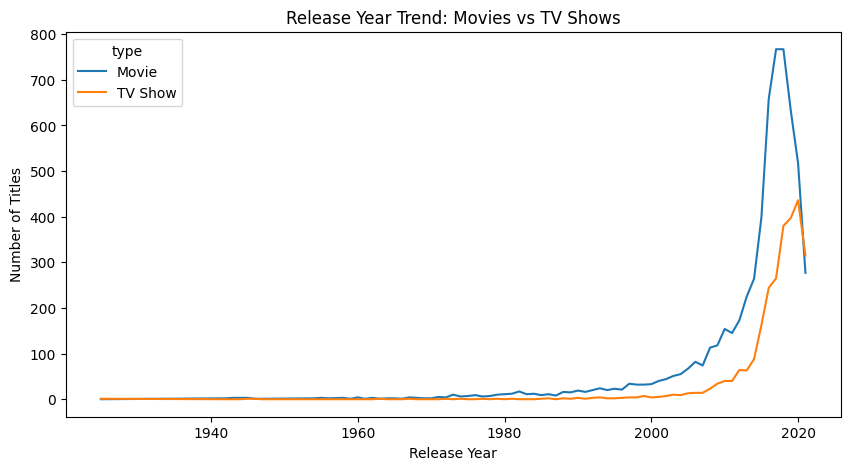

In [ ]:
year_type.plot(
    kind='line',
    figsize=(10, 5)
)

plt.title('Release Year Trend: Movies vs TV Shows')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

Key Findings and Conclusion

The Netflix dataset contains a wide range of Movies and TV Shows from different countries, release years, ratings, genres, and creators.

Key Findings Movies make up a larger proportion of the dataset than TV Shows. The United States appears most frequently among the countries associated with Netflix titles. 2018 has the highest number of titles by release year in the dataset. TV-MA is the most common content rating. Most movies fall within the 91–120 minute duration category. Most TV Shows have a relatively small number of seasons, with 1 season being the most common. International Movies and Dramas are among the most frequently occurring genres. The dataset contains titles from many different directors and actors. The number of titles added to Netflix varies across different years and months. Conclusion

This exploratory data analysis provided an overview of Netflix's content library and revealed patterns in content type, countries, release years, ratings, duration, seasons, genres, directors, actors, and title additions.

The analysis demonstrates how data cleaning, aggregation, filtering, comparison, and visualization can be used to extract meaningful insights from a real-world dataset.